<a href="https://colab.research.google.com/github/kaluarachchiteshan/agromaster-risk-calculation-ml/blob/04-features/notebooks/04_features_and_target.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# 04 - Feature engineering and target ratio (proposal 4.4 and 4.5) | Group 41 AgroMaster
from google.colab import drive
drive.mount('/content/drive')

import os, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

OUT_DIR = "/content/drive/MyDrive/agromaster"
FIG_DIR = os.path.join(OUT_DIR, "figures"); os.makedirs(FIG_DIR, exist_ok=True)
KEYS = ["state", "district", "market", "commodity", "variety", "grade"]   # one series = one combination
PRICES = ["min_price", "max_price", "modal_price"]

# ---------------- CONFIG (from the proposal) ----------------
HORIZON     = 7      # predict 7 calendar days ahead
HIST_DAYS   = 90     # trailing window for the historical average in the target ratio
FFILL_LIMIT = 3      # forward-fill predictor prices for at most 3 consecutive days
MIN_HIST    = 30     # "sufficient history": at least 30 observed prices in the 90-day window
SEASONS = {12: "Winter", 1: "Winter", 2: "Winter", 3: "Summer", 4: "Summer", 5: "Summer",
           6: "Monsoon", 7: "Monsoon", 8: "Monsoon", 9: "Monsoon", 10: "Post-monsoon", 11: "Post-monsoon"}
# ------------------------------------------------------------

df = pd.read_parquet(os.path.join(OUT_DIR, "agmarknet_clean.parquet"))
df = df.sort_values(KEYS + ["date"], kind="stable").reset_index(drop=True)
df["sid"] = df.groupby(KEYS, observed=True).ngroup()               # integer id per series
series_keys = df.drop_duplicates("sid")[["sid"] + KEYS]            # lookup table: sid -> series identity
print(f"{len(df):,} rows | {df['sid'].nunique():,} series")

Mounted at /content/drive
7,715,788 rows | 2,605 series


In [ ]:
# Build features and the target ratio, one series at a time
def build_series(g):
    """g: one series (one row per observed date). Returns one row per usable prediction date t."""
    g = g.set_index("date")[PRICES]
    cal = pd.date_range(g.index[0], g.index[-1], freq="D")
    raw = g.reindex(cal)                         # daily calendar; NaN on days with no report
    f = raw.ffill(limit=FFILL_LIMIT)             # predictor prices, short gaps bridged
    m = f["modal_price"]

    out = pd.DataFrame(index=cal)
    out["min_price"], out["max_price"], out["modal_price"] = f["min_price"], f["max_price"], m
    out["price_spread"]   = f["max_price"] - f["min_price"]
    out["spread_ratio"]   = out["price_spread"] / m
    out["modal_lag_1"]    = m.shift(1)           # shift counts calendar days because the index is daily
    out["modal_lag_7"]    = m.shift(7)
    out["modal_lag_30"]   = m.shift(30)
    out["ma_7"]           = m.rolling(7,  min_periods=4).mean()     # windows end at t: they use t and earlier only
    out["ma_30"]          = m.rolling(30, min_periods=15).mean()
    out["volatility_30"]  = m.rolling(30, min_periods=15).std()
    out["price_momentum"] = m / m.shift(7) - 1                      # 7-day percentage change

    # Target side: built from OBSERVED prices only, never forward-filled
    obs = raw["modal_price"]
    out["future_modal"]  = obs.shift(-HORIZON)                                          # observed modal price at t+7
    out["hist_mean_90"]  = obs.shift(1).rolling(HIST_DAYS, min_periods=MIN_HIST).mean() # the 90 days strictly before t
    out["ratio"]         = out["future_modal"] / out["hist_mean_90"]                    # target ratio r_t
    out["current_ratio"] = obs / out["hist_mean_90"]     # today's price vs the same average (for the persistence baseline)

    keep = obs.notna() & out["ratio"].notna() & out["ma_30"].notna()    # observed day, observed target, enough history
    return out[keep]

t0 = time.time(); parts = []; n = df["sid"].nunique()
for i, (sid, g) in enumerate(df.groupby("sid", sort=False)[["date"] + PRICES]):
    r = build_series(g)
    if len(r):
        r = r.astype("float32").rename_axis("date").reset_index()
        r["sid"] = sid
        parts.append(r)
    if (i + 1) % 250 == 0 or i + 1 == n:
        print(f"{i + 1:,}/{n:,} series | {time.time() - t0:.0f}s")

feat = pd.concat(parts, ignore_index=True); del parts
feat["target_date"] = feat["date"] + pd.Timedelta(days=HORIZON)
feat["month"] = feat["date"].dt.month.astype("int16")
feat["year"] = feat["date"].dt.year.astype("int16")
feat["day_of_year"] = feat["date"].dt.dayofyear.astype("int16")
feat["season"] = feat["month"].map(SEASONS).astype("category")
feat = feat.merge(series_keys, on="sid", how="left")
feat = feat.sort_values(["date", "sid"], kind="stable").reset_index(drop=True)
print(f"\nClean rows in: {len(df):,} -> prediction rows out: {len(feat):,} ({100 * len(feat) / len(df):.1f}% kept)")

250/2,605 series | 5s
500/2,605 series | 8s
750/2,605 series | 11s
1,000/2,605 series | 15s
1,250/2,605 series | 19s
1,500/2,605 series | 22s
1,750/2,605 series | 25s
2,000/2,605 series | 29s
2,250/2,605 series | 33s
2,500/2,605 series | 36s
2,605/2,605 series | 37s

Clean rows in: 7,715,788 -> prediction rows out: 5,784,407 (75.0% kept)


In [ ]:
# The 18 model features (Table 1 of the proposal): 5 native + 13 derived; 15 numerical + 3 categorical
NUM_FEATURES = ["min_price", "max_price", "modal_price", "price_spread", "spread_ratio", "modal_lag_1", "modal_lag_7", "modal_lag_30",
                "ma_7", "ma_30", "volatility_30", "price_momentum", "month", "year", "day_of_year"]
CAT_FEATURES = ["commodity", "state", "season"]
FEATURES = NUM_FEATURES + CAT_FEATURES
assert len(FEATURES) == 18 and len(NUM_FEATURES) == 15 and len(CAT_FEATURES) == 3

print(feat[NUM_FEATURES].describe().T[["mean", "min", "50%", "max"]].round(2).to_string())
miss = feat[FEATURES].isna().sum()
print("\nMissing values in features (a lag is missing when that calendar day had no report within 3 days):")
print((100 * miss[miss > 0] / len(feat)).round(2).astype(str).add(" %").to_string() if miss.sum() else "none")
assert np.isfinite(feat[NUM_FEATURES].fillna(0).to_numpy(dtype="float64")).all(), "infinite values found"

# Leakage check: recompute lag, target and 90-day mean by hand from the clean data for 200 random rows
chk = feat.dropna(subset=["modal_lag_7"]).sample(200, random_state=0)
for row in chk.itertuples():
    s = df.loc[df["sid"] == row.sid].set_index("date")["modal_price"]
    past = s[s.index <= row.date].reindex(pd.date_range(s.index[0], row.date)).ffill(limit=FFILL_LIMIT)
    assert np.isclose(past.iloc[-8], row.modal_lag_7, rtol=1e-4), "lag 7 mismatch"
    assert np.isclose(s[row.target_date], row.future_modal, rtol=1e-4), "target mismatch"
    h = s[(s.index < row.date) & (s.index >= row.date - pd.Timedelta(days=HIST_DAYS))]
    assert np.isclose(h.mean(), row.hist_mean_90, rtol=1e-3), "90-day mean mismatch"
print("\nLeakage check passed on 200 random rows: features use dates <= t, target uses t+7")

                   mean      min      50%       max
min_price       1547.87    20.00  1200.00  40000.00
max_price       1925.72    50.00  1500.00  50000.00
modal_price     1744.51    45.00  1350.00  45000.00
price_spread     377.84     0.00   200.00  23500.00
spread_ratio       0.26     0.00     0.17      9.68
modal_lag_1     1743.65    47.00  1350.00  45000.00
modal_lag_7     1744.64    50.00  1350.00  45000.00
modal_lag_30    1744.71    45.00  1350.00  43000.00
ma_7            1744.29    55.00  1357.14  39800.00
ma_30           1743.71    84.11  1369.83  29519.23
volatility_30    260.22     0.00   164.69  13011.44
price_momentum     0.03    -0.96     0.00     20.88
month              6.51     1.00     7.00     12.00
year            2016.79  2001.00  2018.00   2025.00
day_of_year      182.62     1.00   183.00    366.00

Missing values in features (a lag is missing when that calendar day had no report within 3 days):
modal_lag_1       1.34 %
modal_lag_7       2.23 %
modal_lag_30      3

Development period only:
              p10 (High below)  p30 (Medium below)  median  share ratio < 1
commodity                                                                  
Brinjal                  0.596               0.821   0.980            0.527
Green Chilli             0.598               0.823   0.989            0.516
Onion                    0.619               0.854   1.003            0.493
Potato                   0.656               0.907   1.018            0.456
Tomato                   0.478               0.724   0.933            0.561


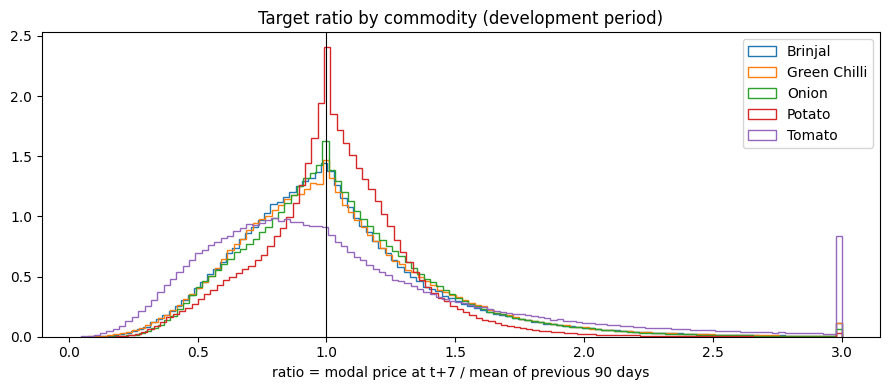


Saved features.parquet: 5,784,407 rows x 29 columns
Rows per commodity (development / test):
col_0         development    test
commodity                        
Brinjal            867195  110156
Green Chilli       778398   99514
Onion             1230845  153051
Potato            1279942  136636
Tomato            1014957  113713
Date range: 2001-08-04 to 2025-10-30


In [ ]:
# Target ratio: exploratory look (model thresholds are re-estimated inside each training fold later)
dev = feat[feat["date"] <= "2023-12-31"]
qs = dev.groupby("commodity", observed=True)["ratio"].quantile([0.10, 0.30, 0.50]).unstack().round(3)
qs.columns = ["p10 (High below)", "p30 (Medium below)", "median"]
qs["share ratio < 1"] = dev.groupby("commodity", observed=True)["ratio"].apply(lambda r: (r < 1).mean()).round(3)
print("Development period only:\n" + qs.to_string())

fig, ax = plt.subplots(figsize=(9, 4))
for c in feat["commodity"].cat.categories:
    ax.hist(dev.loc[dev["commodity"] == c, "ratio"].clip(0, 3), bins=120, histtype="step", density=True, label=c)
ax.axvline(1, color="k", lw=0.8); ax.set_xlabel("ratio = modal price at t+7 / mean of previous 90 days")
ax.set_title("Target ratio by commodity (development period)"); ax.legend()
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "04_target_ratio.png"), dpi=150); plt.show()

# Save
cols = ["sid", "date", "target_date"] + KEYS + [c for c in FEATURES if c not in KEYS] + ["future_modal", "hist_mean_90", "ratio", "current_ratio"]
feat[cols].to_parquet(os.path.join(OUT_DIR, "features.parquet"), compression="zstd", index=False)
json.dump({"num_features": NUM_FEATURES, "cat_features": CAT_FEATURES, "horizon": HORIZON, "hist_days": HIST_DAYS,
           "ffill_limit": FFILL_LIMIT, "min_hist": MIN_HIST, "seasons": {str(k): v for k, v in SEASONS.items()}},
          open(os.path.join(OUT_DIR, "feature_config.json"), "w"), indent=2)
print(f"\nSaved features.parquet: {len(feat):,} rows x {len(cols)} columns")
print("Rows per commodity (development / test):")
print(pd.crosstab(feat["commodity"], np.where(feat["date"] <= "2023-12-31", "development", "test")).to_string())
print(f"Date range: {feat['date'].min().date()} to {feat['date'].max().date()}")